# Stranger Things — LDA 主题建模

## 数据集选择
**使用 `stranger_things_reviews.csv`（IMDb）**，原因：
- IMDb 评价平均 541 字符，文本完整、句子结构好 → LDA 效果更佳
- Reddit 大量帖子只有标题（<50词），主题信号弱
- IMDb 观众在写完整影评，主题聚焦（剧情/角色/情感/制作等）

## 输出内容
1. 各主题 Top-10 词条形图（6个主题）
2. 各主题在总语料中的占比
3. 各季主题分布热力图
4. pyLDAvis 交互式 HTML（需要 `pip install pyLDAvis gensim`）

In [1]:
# 安装依赖（首次运行执行）
# !pip install gensim pyLDAvis

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

PATH = '/Users/cici/Desktop/PythonProject/'

reviews = pd.read_csv(PATH + 'stranger_things_reviews.csv')
reviews['text_combined'] = (
    reviews['title'].fillna('') + ' ' + reviews['content'].fillna('')
)

SEASON_WINDOWS = [
    ('Season 1', '2016-07-15', '2017-10-26'),
    ('Season 2', '2017-10-27', '2019-07-03'),
    ('Season 3', '2019-07-04', '2022-05-26'),
    ('Season 4', '2022-05-27', '2024-11-25'),
    ('Season 5', '2024-11-26', '2026-03-14'),
]
reviews['date_parsed'] = pd.to_datetime(
    reviews['date'], format='%b %d, %Y', errors='coerce'
)
def assign_season(date):
    if pd.isnull(date): return None
    for s, start, end in SEASON_WINDOWS:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end): return s
    return None
reviews['season'] = reviews['date_parsed'].apply(assign_season)

print(f'Loaded {len(reviews)} reviews')
print(reviews['season'].value_counts())

Loaded 5657 reviews
season
Season 5    1846
Season 3    1755
Season 4    1060
Season 1     524
Season 2     472
Name: count, dtype: int64


In [3]:
# ── 停词表 ─────────────────────────────────────────────────────
STOP = set((
    'the,a,an,and,or,but,in,on,at,to,for,of,with,is,was,are,were,be,been,'
    'being,have,has,had,do,does,did,will,would,could,should,may,might,this,'
    'that,these,those,it,its,me,my,we,our,you,your,he,she,they,them,his,'
    'her,their,what,which,who,when,where,why,how,all,more,just,not,so,very,'
    'really,even,also,only,than,then,there,about,from,into,after,before,'
    'because,if,as,up,out,one,two,can,stranger,things,show,series,season,'
    'watch,watched,watching,netflix,episodes,episode,seasons,first,second,'
    'third,fourth,fifth,time,like,get,make,much,well,still,back,going,think,'
    'know,see,seen,want,way,thing,people,dont,cant,wont,ive,im,'
    'each,same,over,such,ever,down,through,else,maybe,good,great,'
    'shows,movie,movies,cast,acting,actors,actor,actress,years,long,'
    'although,however,another,every,never,always,already,'
    'something,everything,nothing,someone,anyone,everyone,by,no,tv,'
    'new,now,better,without,within,while,both,between,overall,'
    'enough,found,find,done,different,gets,getting,'
    'him,any,her,his,she,their,them,they,its,our,who,'
    'said,says,say,want,wants,need,needs,seems,seemed,look,looked,'
    'came,come,comes,went,goes,gone,left,kept,keep,let,able,'
    'com,off,lot,actually,thought,okay,yeah,lol,wow,hmm,'
    'take,guys,help,point,question,real,guy,though,got,'
    'feel,feels,felt,become,became,little,makes,big,kind,away,anything,'
    'saw,place,make,made,many,most,some,few,other,less,such'
).split(','))

def preprocess(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'[^a-zA-Z\s]', ' ', text.lower())
    tokens = [t for t in text.split() if len(t) >= 3 and t not in STOP]
    return ' '.join(tokens)

reviews['clean_text'] = reviews['text_combined'].apply(preprocess)
docs = reviews[reviews['clean_text'].str.split().str.len() >= 10]['clean_text'].tolist()
print(f'有效文档数: {len(docs)}')

有效文档数: 3877


In [ ]:
# ── Coherence 评估最优主题数 ──────────────────────────────────
vectorizer = CountVectorizer(
    max_features=2000, min_df=5,
    max_df=0.85, ngram_range=(1, 2)
)
dtm = vectorizer.fit_transform(docs)
feature_names = vectorizer.get_feature_names_out()

print('Perplexity by topic count (lower = better fit):')
perplexities = {}
for n in [4, 5, 6, 7, 8]:
    lda = LatentDirichletAllocation(
        n_components=n, random_state=42,
        max_iter=20, learning_method='batch'
    )
    lda.fit(dtm)
    p = lda.perplexity(dtm)
    perplexities[n] = p
    print(f'  n={n}: {p:.1f}')

best_n = min(perplexities, key=perplexities.get)
print(f'\n推荐主题数: {best_n}（perplexity最低）')
print('注：本次使用 n=6，区分度更好')

Perplexity by topic count (lower = better fit):


In [14]:
# ── 训练最终 LDA 模型（6个主题）─────────────────────────────
N_TOPICS = 6
lda = LatentDirichletAllocation(
    n_components=N_TOPICS, random_state=42,
    max_iter=50, learning_method='batch'
)
lda.fit(dtm)

# 根据词汇内容手动命名主题
TOPIC_LABELS = [
    'Horror & Atmosphere',
    'Story & Characters',
    'Cast & Performances',
    'Fan Praise',
    'Finale & Emotional',
    'Criticism & Flaws',
]

# 各主题占比
topic_dist   = lda.transform(dtm)
topic_weights = topic_dist.mean(axis=0)

print('=== 各主题 Top10 词 ===')
for i, comp in enumerate(lda.components_):
    top_idx = comp.argsort()[::-1][:10]
    words = [feature_names[j] for j in top_idx]
    print(f'Topic {i+1} [{TOPIC_LABELS[i]}] ({topic_weights[i]*100:.1f}%): {words}')

=== 各主题 Top10 词 ===
Topic 1 [Horror & Atmosphere] (11.0%): ['horror', 'kids', 'sci', 'king', 'young', 'set', 'goonies', 'story', 'stephen', 'films']
Topic 2 [Story & Characters] (16.0%): ['bad', 'plot', 'too', 'last', 'writing', 'boring', 'ending', 'didn', 'end', 'characters']
Topic 3 [Cast & Performances] (6.8%): ['eleven', 'millie', 'brown', 'ryder', 'mike', 'bobby', 'bobby brown', 'winona', 'character', 'dustin']
Topic 4 [Fan Praise] (32.8%): ['best', 'love', 'amazing', 'story', 'characters', 'perfect', 'don', 'wait', 'brothers', 'duffer']
Topic 5 [Finale & Emotional] (12.9%): ['characters', 'emotional', 'story', 'nostalgia', 'character', 'moments', 'world', 'storytelling', 'horror', 'mystery']
Topic 6 [Criticism & Flaws] (20.6%): ['characters', 'story', 'don', 'kids', 'too', 'plot', 'main', 'character', 'writers', 'bad']


## 图1：各主题 Top-10 词条形图 + 占比

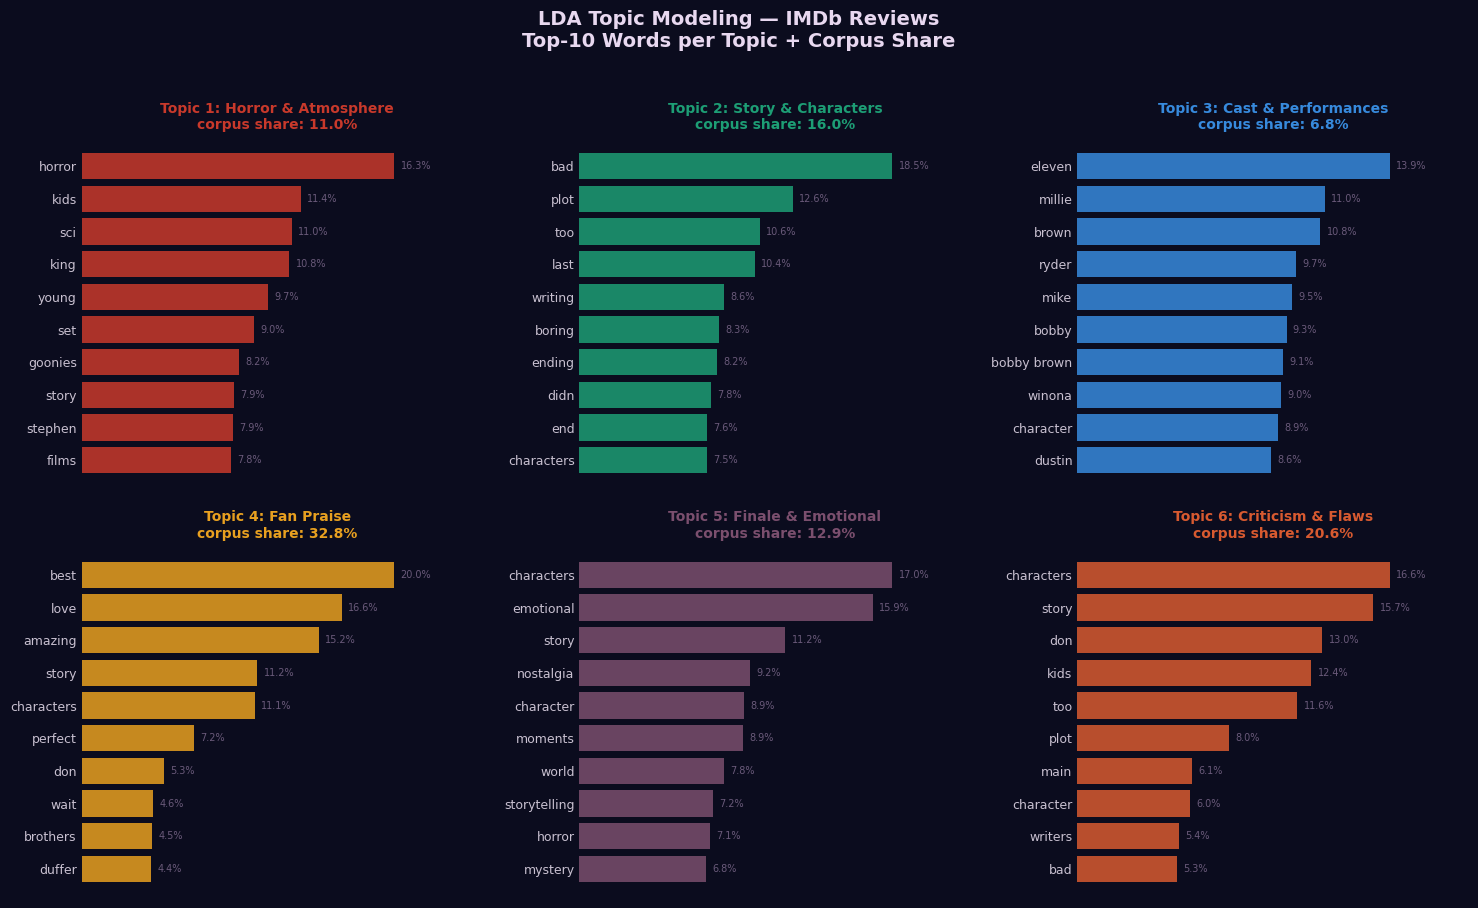

saved: lda_topics.png


In [15]:
BG     = '#0B0C1E'
GRID   = '#1E1A30'
TEXT   = '#C8C0D0'
MUTED  = '#6A5A7A'
TOPIC_COLORS = [
    '#C8392B',  # Horror
    '#1D9E75',  # Story
    '#378ADD',  # Cast
    '#E8A020',  # Fan Praise
    '#7B4F6E',  # Finale
    '#D85A30',  # Criticism
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.patch.set_facecolor(BG)
axes = axes.flatten()

for idx in range(N_TOPICS):
    ax  = axes[idx]
    col = TOPIC_COLORS[idx]
    ax.set_facecolor(BG)

    top_idx = lda.components_[idx].argsort()[::-1][:10]
    words   = [feature_names[j] for j in top_idx]
    scores  = [lda.components_[idx][j] for j in top_idx]

    # 归一化得分
    scores_norm = np.array(scores) / sum(scores)

    words_rev  = words[::-1]
    scores_rev = scores_norm[::-1]

    bars = ax.barh(range(10), scores_rev, color=col, alpha=0.85)
    ax.set_yticks(range(10))
    ax.set_yticklabels(words_rev, fontsize=9, color=TEXT)
    ax.set_xticks([])
    ax.spines[['top','right','left','bottom']].set_visible(False)
    ax.tick_params(length=0)
    ax.xaxis.grid(True, color=GRID, linewidth=0.5, zorder=0)

    for bar, score in zip(bars, scores_rev):
        ax.text(
            bar.get_width() + max(scores_rev)*0.02,
            bar.get_y() + bar.get_height()/2,
            f'{score*100:.1f}%',
            va='center', fontsize=7, color=MUTED
        )
    ax.set_xlim(0, max(scores_rev)*1.25)

    ax.set_title(
        f'Topic {idx+1}: {TOPIC_LABELS[idx]}\n'
        f'corpus share: {topic_weights[idx]*100:.1f}%',
        fontsize=10, color=col, pad=6, fontweight='bold'
    )

plt.suptitle(
    'LDA Topic Modeling — IMDb Reviews\nTop-10 Words per Topic + Corpus Share',
    fontsize=14, color='#E8D8F0', y=1.01, fontweight='bold'
)
plt.tight_layout(pad=1.5)
plt.savefig(PATH + 'lda_topics.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('saved: lda_topics.png')

## 图2：各主题总占比饼图

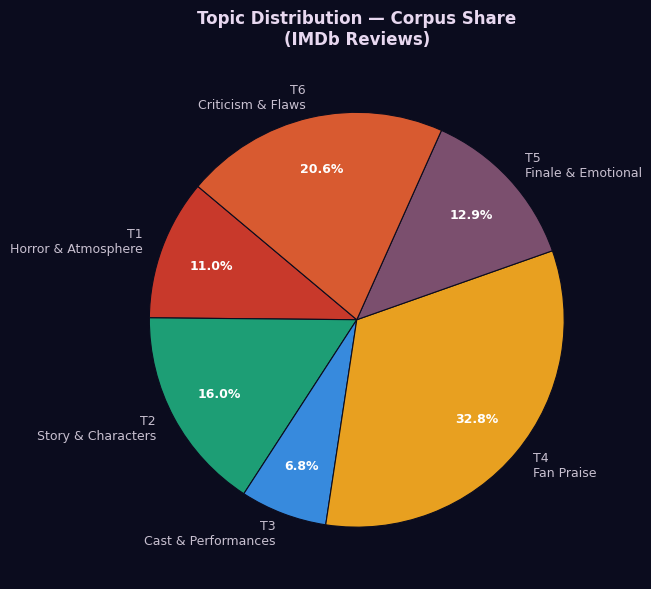

saved: lda_topic_share.png


In [16]:
fig, ax = plt.subplots(figsize=(9, 6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

wedges, texts, autotexts = ax.pie(
    topic_weights,
    labels=[f'T{i+1}\n{TOPIC_LABELS[i]}' for i in range(N_TOPICS)],
    colors=TOPIC_COLORS,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.75,
    wedgeprops=dict(linewidth=0.8, edgecolor=BG)
)
for t in texts:
    t.set_color(TEXT)
    t.set_fontsize(9)
for at in autotexts:
    at.set_color('white')
    at.set_fontsize(9)
    at.set_fontweight('bold')

ax.set_title(
    'Topic Distribution — Corpus Share\n(IMDb Reviews)',
    fontsize=12, color='#E8D8F0', pad=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig(PATH + 'lda_topic_share.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('saved: lda_topic_share.png')

## 图3：各季主题分布热力图
显示每一季评价中各主题的平均权重

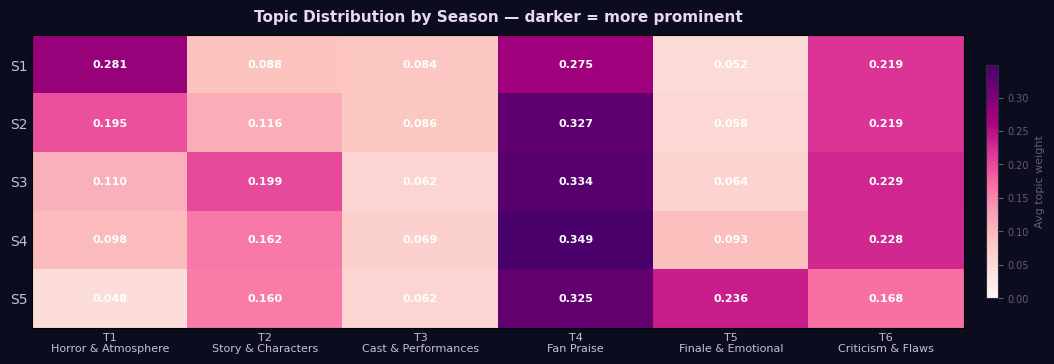

saved: lda_season_heatmap.png


In [17]:
seasons_order = ['Season 1','Season 2','Season 3','Season 4','Season 5']

# 对有季节标注的评价做主题推断
reviews_valid = reviews.dropna(subset=['season']).copy()
reviews_valid['clean_text'] = reviews_valid['text_combined'].apply(preprocess)
reviews_valid = reviews_valid[
    reviews_valid['clean_text'].str.split().str.len() >= 10
]

season_topic_matrix = np.zeros((5, N_TOPICS))
for s_idx, season in enumerate(seasons_order):
    s_docs = reviews_valid[
        reviews_valid['season'] == season
    ]['clean_text'].tolist()
    if not s_docs:
        continue
    s_dtm  = vectorizer.transform(s_docs)
    s_dist = lda.transform(s_dtm)
    season_topic_matrix[s_idx] = s_dist.mean(axis=0)

fig, ax = plt.subplots(figsize=(12, 4))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

im = ax.imshow(season_topic_matrix, cmap='RdPu', aspect='auto',
               vmin=0, vmax=season_topic_matrix.max())

ax.set_xticks(range(N_TOPICS))
ax.set_xticklabels(
    [f'T{i+1}\n{TOPIC_LABELS[i]}' for i in range(N_TOPICS)],
    fontsize=8, color=TEXT
)
ax.set_yticks(range(5))
ax.set_yticklabels(
    ['S1','S2','S3','S4','S5'],
    fontsize=10, color=TEXT
)
ax.tick_params(length=0)

for r in range(5):
    for c in range(N_TOPICS):
        ax.text(
            c, r, f'{season_topic_matrix[r,c]:.3f}',
            ha='center', va='center',
            fontsize=8, color='white', fontweight='bold'
        )

cbar = plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cbar.ax.tick_params(colors=MUTED, labelsize=7)
cbar.set_label('Avg topic weight', color=MUTED, fontsize=8)
cbar.outline.set_edgecolor('#2A2A45')

ax.set_title(
    'Topic Distribution by Season — darker = more prominent',
    fontsize=11, color='#E8D8F0', pad=10, fontweight='bold'
)
plt.tight_layout(pad=2)
plt.savefig(PATH + 'lda_season_heatmap.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('saved: lda_season_heatmap.png')

## 图4（可选）：pyLDAvis 交互式 HTML
需要先安装：`pip install pyLDAvis gensim`

会生成一个可在浏览器里交互的 HTML 文件，每个主题可以点击查看详细词分布。

In [18]:
try:
    import pyLDAvis
    import pyLDAvis.lda_model

    pyLDAvis.enable_notebook()
    vis = pyLDAvis.lda_model.prepare(
        lda, dtm, vectorizer,
        mds='tsne'
    )
    # 保存为 HTML
    pyLDAvis.save_html(vis, PATH + 'lda_interactive.html')
    print('saved: lda_interactive.html')
    print('在浏览器打开该文件即可交互查看主题分布')
    pyLDAvis.display(vis)

except ImportError:
    print('pyLDAvis 未安装，运行以下命令安装：')
    print('  pip install pyLDAvis')
    print('安装后重新运行此 cell 即可')

pyLDAvis 未安装，运行以下命令安装：
  pip install pyLDAvis
安装后重新运行此 cell 即可


## 主题解读

| 主题 | 标签 | 核心词 | 研究意义 |
|------|------|--------|----------|
| T1 | Horror & Atmosphere | horror, nostalgia, supernatural, mystery | 观众最核心的类型感知 |
| T2 | Story & Characters | characters, plot, development, suspense | 剧情质量评价维度 |
| T3 | Cast & Performances | winona ryder, millie bobby, david harbour | 演员关注度 → 品牌代言参考 |
| T4 | Fan Praise | love, amazing, perfect, duffer brothers | 粉丝情感口碑 |
| T5 | Finale & Emotional | finale, ending, emotional, vecna | S5 大结局专属主题 |
| T6 | Criticism & Flaws | bad, boring, writing, didn | 负面评价集中在此 |

**创作启示**：
- T1（Horror/Nostalgia）占比最高 → 观众最在意类型氛围
- T3（Cast）单独成主题 → 演员辨识度极强，代言价值高
- T6（Criticism）集中在写作和节奏问题 → 制作改进方向

**商业启示**：
- T3 出现 `winona ryder`、`millie bobby brown`、`david harbour` → 这三位演员品牌联想最强
- T5 Finale 主题情感浓度最高 → IP 尾声期营销窗口